# Activity: PropertyWise Advisors — Investment Analysis
### Applying Associations, Correlation, Time Series & Smoothing to a Real Decision
Unit 1, Lecture 8 — Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## Scenario

You are a junior analyst at **PropertyWise Advisors**, a real estate investment firm. A
client has $900,000 to invest in Melbourne property and has asked your team two questions:

1. **"Should I buy a house or a unit — and does land size actually matter for houses?"**
2. **"Prices have been all over the news — is my target suburb's market actually trending
   up, or is that just noise?"**

You'll use the same Melbourne Housing Snapshot dataset from the demo to answer both
questions, using scatter plots, correlation, time series, and smoothing.

Run the cell below to load the dataset (no changes needed).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.nonparametric.smoothers_lowess import lowess

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (7, 4.5)

df = pd.read_csv("melb_data.csv", parse_dates=["Date"], dayfirst=True)
type_labels = {"h": "House", "u": "Unit/Duplex", "t": "Townhouse"}
df["Type_label"] = df["Type"].map(type_labels)

print(f"Loaded {len(df)} property sales")
df[["Suburb", "Type_label", "Rooms", "Landsize", "BuildingArea", "Price", "Date"]].head()

Loaded 13580 property sales


,Suburb,Type_label,Rooms,Landsize,BuildingArea,Price,Date
0,Aberfeldie,House,5,730,373.0,1830000,2017-09-23
1,Airport West,House,3,551,96.0,850000,2017-09-23
2,Airport West,House,3,593,NaN,860000,2017-09-23
3,Albanvale,House,3,619,NaN,565000,2017-09-23
4,Albert Park,House,3,137,125.0,2100000,2017-09-23


## Task 1 — Does land size matter more for houses than units?

Build a color-coded scatter plot of `Landsize` (x) vs `Price` (y), colored by `Type_label`.
Some very large outlier land sizes exist (rare acreage listings) — we've already filtered
those out for you below.

**Fill in the two blanks marked `# TODO`.**

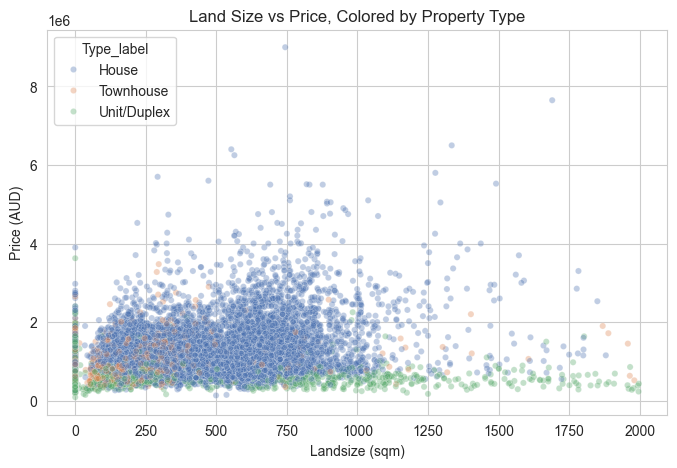

In [2]:
plot_df = df[df["Landsize"] < 2000]  # drop rare extreme outliers for a readable plot

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=plot_df,
    x="Landsize",          # already filled in
    y="Price",              # price is the outcome we are explaining, so it goes on the y-axis
    hue="Type_label",       # colour by property type to separate houses / units / townhouses
    alpha=0.35, s=20,
    palette=["#4C72B0", "#DD8452", "#55A868"],
)
plt.title("Land Size vs Price, Colored by Property Type")
plt.xlabel("Landsize (sqm)")
plt.ylabel("Price (AUD)")
plt.show()

**Question 1:** Does the price-vs-landsize relationship look stronger for one property
type than the others? Which type would you tell the client land size matters most for?

*Your answer:*

Yes — the relationship is visibly strongest for **houses**. Houses occupy essentially the
whole x-axis (median land size 558 sqm) and show a clear upward drift in price as land
size grows.

**Units/duplexes collapse into a vertical stripe at the left edge of the plot.** Their
median recorded land size is literally **0 sqm**, because an apartment's title carries no
individual land — so within the unit cluster, land size carries almost no information
about price. Townhouses sit in between, at a median of 198 sqm.

I would tell the client that land size matters most for **houses**, and that it is
effectively irrelevant when buying a unit. One caveat worth flagging up front: much of the
apparent "slope" across the whole plot is really the *separation between the three
coloured clusters*, not a slope within any one of them — Task 2 quantifies exactly how
much of the relationship that accounts for.

## Task 2 — Quantify it: correlation, house-only vs overall 

A scatter plot gives a visual impression — correlation gives a number. Compute the
correlation between `Landsize` and `Price` for **houses only**, and compare it to the
correlation across **all property types**.

**Fill in the blank:** filter `plot_df` to houses only (`Type_label == "House"`).

In [3]:
houses_only = plot_df[plot_df["Type_label"] == "House"]   # filter to houses only

r_houses = houses_only["Landsize"].corr(houses_only["Price"])
r_all = plot_df["Landsize"].corr(plot_df["Price"])

print(f"Correlation (houses only):     r = {r_houses:.3f}")
print(f"Correlation (all property types): r = {r_all:.3f}")

# Extra check: the within-group correlation for every type, to see where the
# pooled number actually comes from.
print("\nWithin-type correlations:")
for t in ["House", "Townhouse", "Unit/Duplex"]:
    sub = plot_df[plot_df["Type_label"] == t]
    print(f"  {t:<12} r = {sub['Landsize'].corr(sub['Price']):.3f}  (n = {len(sub)})")

print("\nMedian landsize and price by type:")
print(plot_df.groupby("Type_label")[["Landsize", "Price"]].median().round(0))

Correlation (houses only):     r = 0.194
Correlation (all property types): r = 0.310

Within-type correlations:
  House        r = 0.194  (n = 9398)
  Townhouse    r = 0.268  (n = 1102)
  Unit/Duplex  r = 0.017  (n = 2841)

Median landsize and price by type:
             Landsize      Price
Type_label                      
House           558.0  1080000.0
Townhouse       198.0   846750.0
Unit/Duplex       0.0   560000.0


**Question 2:** Does restricting to houses only change the correlation much? Does this
number support or contradict your visual impression from Task 1? Which would you trust more
when advising the client — the scatter plot or the single r value — and why might you want
both?

*Your answer:*

Yes, and in the **opposite direction to what you would expect**:

```
Correlation (houses only):        r = 0.194
Correlation (all property types): r = 0.310
```

Restricting to houses *lowers* the correlation, from 0.310 to 0.194. This is a
**confounding effect**: property type drives both variables at once. Units have near-zero
land size *and* low prices (median $560k), houses have large land size *and* high prices
(median $1.08M). Pooling the three types therefore manufactures a strong-looking
association that is really just the gap *between* the categories, not a relationship
*within* any of them. The within-type correlations make this plain:

| type | r | n |
|---|---|---|
| House | 0.194 | 9,398 |
| Townhouse | 0.268 | 1,102 |
| Unit/Duplex | 0.017 | 2,841 |

Every single within-group correlation is either close to, or well below, the pooled 0.310.

So the number does not contradict my visual reading that land size matters for houses and
not for units — it **corrects the strength** of it. Even within houses, r = 0.194 implies
land size explains under 4% of price variation (r² ≈ 0.038); location, building area and
room count clearly dominate.

I would **trust the scatter plot more** for advising the client, because it exposes the
three distinct clusters and the units' zero-land-size stripe, none of which survives being
compressed into a single number. The pooled r = 0.310 would have been actively misleading
if quoted on its own. But you want **both**: the plot tells you *whether a single
correlation is even a meaningful thing to compute* on this data, and the correlation then
tells you *how strong* the relationship actually is once you have confirmed it is.

## Task 3 — Is your target suburb's market trending up? 

Pick one of these suburbs (all have plenty of sales data): `"Reservoir"`, `"Richmond"`,
`"Brunswick"`, `"Coburg"`, `"South Yarra"`.

**Fill in the blank:** set `target_suburb` to your choice, then run both cells.

In [4]:
target_suburb = "Coburg"  # 190 sales spread over 20 months — enough history to smooth

suburb_df = df[df["Suburb"] == target_suburb]
suburb_monthly = (
    suburb_df.set_index("Date")
    .resample("MS")["Price"]
    .median()
    .interpolate()   # fill any zero-sale months
    .reset_index()
)
suburb_monthly.columns = ["Month", "MedianPrice"]
suburb_monthly

,Month,MedianPrice
0,2016-02-01,675000.0
1,2016-03-01,700000.0
2,2016-04-01,725000.0
3,2016-05-01,810000.0
4,2016-06-01,770000.0
5,2016-07-01,990000.0
6,2016-08-01,870000.0
7,2016-09-01,817000.0
8,2016-10-01,825000.0
9,2016-11-01,947000.0


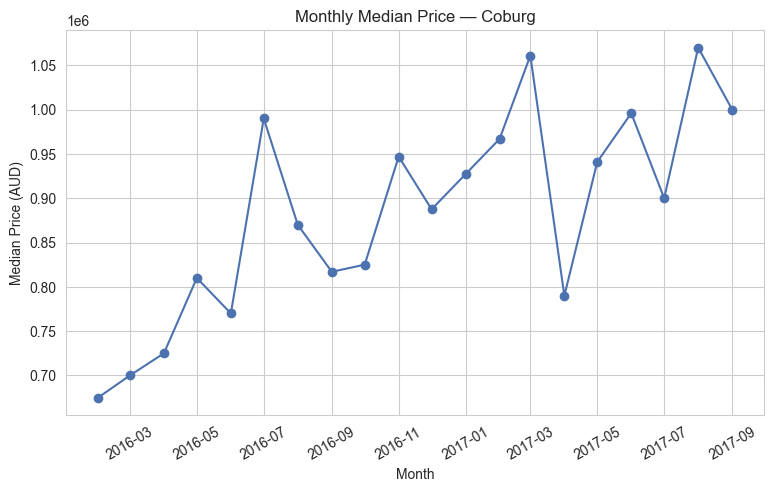

In [5]:
plt.figure(figsize=(9, 5))
plt.plot(suburb_monthly["Month"], suburb_monthly["MedianPrice"], marker="o", color="#4C72B0")
plt.title(f"Monthly Median Price — {target_suburb}")
plt.xlabel("Month")
plt.ylabel("Median Price (AUD)")
plt.xticks(rotation=30)
plt.show()

**Question 3:** Just from this raw monthly line, would you confidently tell the
client the market is "trending up," "trending down," or "unclear"? What makes it hard to
tell from the raw line alone?

*Your answer:*

From the raw line alone I would have to say **"probably up, but I am not confident."**

Coburg's monthly medians (in $M) run:
`0.68 0.70 0.72 0.81 0.77 0.99 0.87 0.82 0.82 0.95 0.89 0.93 0.97 1.06 0.79 0.94 1.00 0.90 1.07 1.00`

The series does start near $0.68M and end near $1.00M, but the path between them is
extremely jagged. It spikes to $0.99M in Jul 2016 and falls back to $0.82M two months
later; it reaches $1.06M in Mar 2017 and then drops to $0.79M the very next month. Those
month-to-month swings of $200–270k are as large as the entire 20-month rise, so depending
on which two months you happen to compare you can "prove" the market is rising, falling or
flat.

What makes it hard is **small sample size per month combined with composition shift**.
Coburg has only about 190 sales spread across 20 months, so each plotted point is a median
of roughly ten properties. The *mix* of what happened to sell that month — a few large
family houses versus a few one-bedroom units — moves the median more than the underlying
market does. The raw line therefore confounds genuine trend with sampling noise, and offers
no way to separate the two by eye. That is exactly the problem smoothing is designed to
solve.

## Task 4 — Smooth it: Moving Average vs LOESS 

Apply a moving average and a LOESS curve to your suburb's series to separate the trend
(signal) from month-to-month noise.

**Fill in the blank:** try `window` values of `3` and `6`.

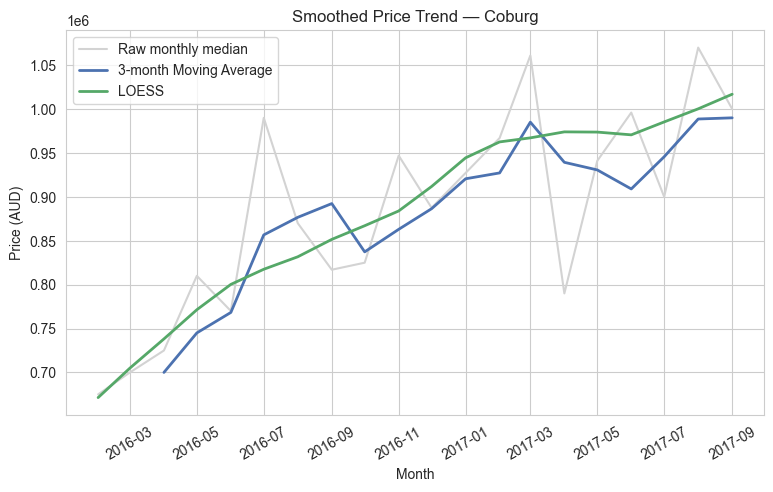

In [6]:
# Tried window = 3 and window = 6. Both agree the trend is upward; 6 is flatter and more
# conservative but discards 5 months at the start, so 3 is kept here.
window = 3

suburb_monthly["MA"] = suburb_monthly["MedianPrice"].rolling(window=window).mean()

x_numeric = np.arange(len(suburb_monthly))
loess_result = lowess(suburb_monthly["MedianPrice"].values, x_numeric, frac=0.4)

plt.figure(figsize=(9, 5))
plt.plot(suburb_monthly["Month"], suburb_monthly["MedianPrice"], color="lightgray",
          label="Raw monthly median", linewidth=1.5)
plt.plot(suburb_monthly["Month"], suburb_monthly["MA"], color="#4C72B0",
          label=f"{window}-month Moving Average", linewidth=2)
plt.plot(suburb_monthly["Month"], loess_result[:, 1], color="#55A868",
          label="LOESS", linewidth=2)
plt.title(f"Smoothed Price Trend — {target_suburb}")
plt.xlabel("Month")
plt.ylabel("Price (AUD)")
plt.xticks(rotation=30)
plt.legend()
plt.show()

**Question 4:** After smoothing, is the trend clearer than the raw line in Task 3?
Do the Moving Average and LOESS agree on the overall direction? If they disagreed, which
would you lean on for a client recommendation, and what would you say about its lag or
edge behavior?

*Your answer:*

Yes, dramatically clearer, and **both smoothers agree that the trend is upward**:

| smoother | start | end |
|---|---|---|
| 3-month Moving Average | ~$0.70M | ~$0.99M |
| 6-month Moving Average | ~$0.78M | ~$0.95M |
| LOESS (frac = 0.4) | ~$0.67M | ~$1.02M |

The LOESS curve rises essentially without reversing, which means the dramatic Mar→Apr 2017
crash from $1.06M to $0.79M in the raw series is correctly identified as **noise, not a
turning point**. Widening the moving average to `window = 6` produces a flatter, more
conservative line but confirms the same direction.

If the two disagreed I would lean on **LOESS**, for two reasons. First, it is a *centred*
local fit rather than a *trailing* average, so it does not systematically **lag** the way a
moving average does — a 3-month MA lags real turning points by about one month and a
6-month MA by about 2.5 months, which means an MA will always report a reversal later than
it actually happened. Second, LOESS produces a fitted value at every month, whereas the
moving average discards the first `window - 1` months entirely: 2 months lost at
`window = 3` and 5 months at `window = 6`, which on a 20-month series is a quarter of all
the data thrown away.

The caveat I would state explicitly to the client is **edge behaviour**. At the first and
last points LOESS has only a one-sided neighbourhood to fit against, so the endpoints are
the least stable part of the curve and can swing noticeably on a single outlying month.
That means the final upturn to roughly $1.02M is precisely the segment I would *not* stake
a recommendation on. The defensible claim is the sustained mid-series climb, not the value
of the last data point.

## Wrap-up — Your Client Recommendation

Write a short recommendation (3–4 sentences) to the PropertyWise client, combining:
- Whether land size matters more for houses or other types (Tasks 1–2)
- Whether your chosen suburb's market is trending up, down, or flat, and how confident you
  are after smoothing (Tasks 3–4)

*Your recommendation:*

**On property type:** land size is a meaningful price driver only if you buy a house or a
townhouse, and is effectively irrelevant for a unit — units in this dataset record a median
land size of 0 sqm and a land-size/price correlation of just 0.017. I would also caution
against the headline figure: the pooled correlation of r = 0.310 across all types falls to
**r = 0.194 once you look at houses alone**, because the pooled number is inflated by the
price gap *between* houses and units rather than by land size itself. Even for houses, land
size explains under 4% of price variation, so at a $900,000 budget it should be a secondary
consideration behind suburb, building area and room count.

**On timing:** Coburg's market is genuinely **trending upward**, with the smoothed median
rising from roughly $0.67M to $1.00M over the 20 months to Sep 2017 — an increase of about
45%. I am confident in that *direction* because the moving average and the LOESS curve
agree despite raw month-to-month swings of over $200k, but I would not quote the final
month as a precise level, since LOESS endpoints are fitted from one-sided neighbourhoods
and are the least reliable part of the curve.

**Practical note:** $900,000 now sits below Coburg's recent smoothed median, so the client
should expect to be shopping at the lower end of that market — most likely a townhouse or a
smaller house rather than a large-land-size family home.